## Evaluating a Model on Validation Dataset
In this notebook, we'll load a saved model, evaluate it on the validation dataset using the Dice score, and visualize prediction.

---

### 1. Import Libraries
Let's start by importing the necessary libraries.

In [1]:
import os
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import numpy as np
from tqdm.notebook import tqdm
import nibabel as nib
from scipy.ndimage import zoom

from dataset_seg import get_image_and_label_paths, ImgSegDataset
from model_seg import UNet

---
### 2. Prepare the Validation Dataset
We need to load our validation dataset using the `DataLoader`.

In [2]:
root_dir = "data/processed/preprocessed_ircadb_liver_dataset"
val_dir = os.path.join(root_dir, "val")

# Get image and label paths for validation datasets
val_image_paths, val_label_paths = get_image_and_label_paths(val_dir)

print(f"Validation dataset: {len(val_image_paths)} images, {len(val_label_paths)} labels\n")

Validation dataset: 582 images, 582 labels



In [3]:
# Load Validation Dataset
val_dataset = ImgSegDataset(val_image_paths, val_label_paths, None)
val_loader = DataLoader(val_dataset, batch_size=1, shuffle=False)

print(f"Length of validation dataset: {len(val_loader)}")

Length of validation dataset: 582


---
### 3. Define Device

We check if a GPU is available and define the device to use for training.

In [4]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


---
### 4. Load the Saved Model
We will load the model and the saved weights.

In [5]:
weights_path = os.path.join("data", "model_weights", "seg_liver_epoch20.pth")

# Load Saved Model
model = UNet().to(device)
model.load_state_dict(torch.load(weights_path, map_location=device))      # load the saved weights
model.eval()  # Set the model to evaluation mode

UNet(
  (enc1): Sequential(
    (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
  )
  (enc2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
  )
  (enc3): Sequential(
    (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
  )
  (dec2): Sequential(
    (0): Conv2d(384, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
  )
  (dec1): Sequential(
    (0): Conv2d(192, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(64, 64, kernel_size=(3

---
### 5. Define the Dice Score Function
The **Dice score** is a measure of overlap between two sets. It is used to measure the accuracy of image segmentation. We define a function to compute this score.

In [6]:
def dice_coefficient(pred, target, smooth=1e-8):
    pred_flat = pred.view(-1)
    target_flat = target.view(-1)
    intersection = (pred_flat * target_flat).sum()
    dice_score = (2.0 * intersection + smooth) / (pred_flat.sum() + target_flat.sum() + smooth)
    return dice_score

---
### 6. Compute Dice Scores for Validation Data
We will pass each sample from the validation dataset through the model, compute the Dice score, and store the scores in a list.

In [7]:
# Compute Dice Scores for Validation Data
dice_scores = []
with torch.no_grad():
    for inputs, targets in tqdm(val_loader):
        inputs = inputs.to(device)
        targets = targets.to(device)

        predictions = model(inputs)

        # Convert model outputs to binary mask (threshold = 0.5)
        predictions = (predictions > 0.5).float()

        # Compute Dice score for each sample
        score = dice_coefficient(predictions, targets)
        dice_scores.append(score.item())

# Convert Dice scores to numpy array
dice_scores = np.array(dice_scores)

  0%|          | 0/582 [00:00<?, ?it/s]

---
### 7. Analyzing Dice Scores
We calculate the mean and standard deviation of Dice scores to summarize performance and use a boxplot to visualize their distribution.

In [8]:
# Compute Mean and STD Dice scores
mean_dice = np.mean(dice_scores)
std_dice = np.std(dice_scores)

print(f"Mean Dice Score: {mean_dice:.3f}")
print(f"STD Dice Score: {std_dice:.3f}")

Mean Dice Score: 0.631
STD Dice Score: 0.395


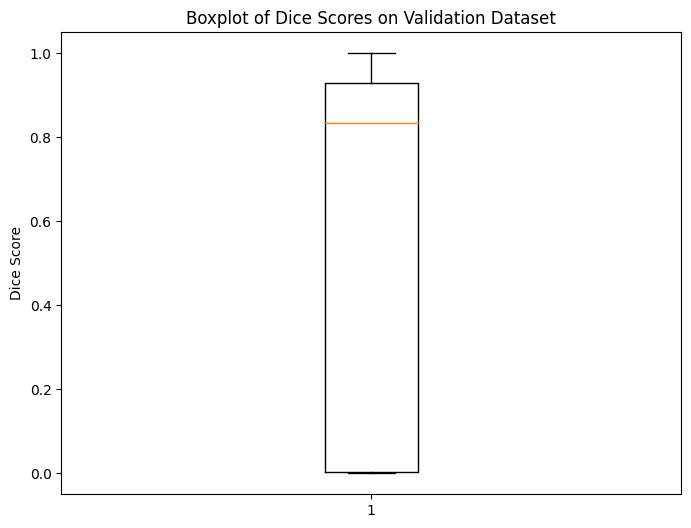

In [9]:
# Plotting Boxplot for Dice Scores
plt.figure(figsize=(8, 6))
plt.boxplot(dice_scores)
plt.title("Boxplot of Dice Scores on Validation Dataset")
plt.ylabel("Dice Score")
plt.show()

---
### 8. Visualizing Model Prediction on Full Volume
In this section, we will load a test subject, make predictions slice-by-slice using the model, and visualize the segmentation of the full 3D volume. This builds upon the model we previously evaluated.

#### 8.1 Load a Test Subject
We will start by loading a sample image from the test dataset. This image represents a 3D volume of the heart, and we'll use the model to predict the segmentation mask slice by slice.

In [10]:
sample_image_path = os.path.join("data", "processed", "3d_ircadb__nifti_liver", "3dircadb1_20_image.nii.gz")
sample_label_gt_path = os.path.join("data", "processed", "3d_ircadb__nifti_liver", "3dircadb1_20_mask_liver.nii.gz")

In [11]:
image = nib.load(sample_image_path)
image_arr = image.get_fdata()
image_spacing = image.header.get_zooms()

label = nib.load(sample_label_gt_path)
label_arr = label.get_fdata()

#### 8.2 Apply Preprocessing and Predict Segmentation for Each Slice
Here, we apply resample, normalization and pad/crop like training step to the loaded image volume.<br>

In [12]:
### Resampling
new_spacing = (2.5, 2.5, image_spacing[-1])
resize_factor = np.array(image_spacing) / np.array(new_spacing)

resampled_img = zoom(image_arr, resize_factor, order=2)
resampled_mask = zoom(label_arr, resize_factor, order=0)

print("Image shape before resampling:", image_arr.shape)
print("Image shape after resampling:", resampled_img.shape)

Image shape before resampling: (512, 512, 225)
Image shape after resampling: (166, 166, 225)


In [13]:
def min_max_normalize(data):
    return (data - np.min(data)) / (np.max(data) - np.min(data))

normalized_img = min_max_normalize(resampled_img)

In [14]:
### Function to pad or crop an array (image or mask) to a specific size
def pad_or_crop_array(input_array, target_size=(128, 128)):
    current_height, current_width = input_array.shape  # Get the current size
    target_height, target_width = target_size  # The desired size

    ### Padding: If the array is smaller than the target size
    if current_height < target_height or current_width < target_width:
        ### Calculate how much padding is needed
        pad_top = max(0, (target_height - current_height) // 2)
        pad_bottom = max(0, target_height - current_height - pad_top)
        pad_left = max(0, (target_width - current_width) // 2)
        pad_right = max(0, target_width - current_width - pad_left)

        ### Apply padding (filling with zeros)
        input_array = np.pad(input_array, [(pad_top, pad_bottom), (pad_left, pad_right)], mode='constant', constant_values=0)

        ### Update current shape after padding
        current_height, current_width = input_array.shape

    ### Cropping: If the array is still larger than the target size
    if current_height > target_height or current_width > target_width:
        ### Calculate where to crop and ensure no negative indices
        crop_top = max(0, (current_height - target_height) // 2)
        crop_bottom = min(current_height, crop_top + target_height)
        crop_left = max(0, (current_width - target_width) // 2)
        crop_right = min(current_width, crop_left + target_width)

        ### Apply cropping
        input_array = input_array[crop_top:crop_bottom, crop_left:crop_right]

    return input_array

We will now pass each 2D slice of the 3D volume through the model to obtain the predicted segmentation mask. We'll apply the threshold the output to create a binary mask.

In [15]:
preds = []
for i in range(normalized_img.shape[-1]):
    img_slice = normalized_img[:, :, i]

    ### Resize
    resized_img_slice = pad_or_crop_array(img_slice, target_size=(128, 128))

    ### Convert to tensor
    slice_tensor = torch.tensor(resized_img_slice).unsqueeze(0).unsqueeze(0).float().to(device)

    with torch.no_grad():
        pred_tensor = model(slice_tensor)
        pred = pred_tensor.cpu().detach().numpy()[0][0]
        pred = pred > 0.5  # Convert model outputs to binary mask (threshold = 0.5)

    preds.append(pred)

In [16]:
preds = np.array(preds).transpose(1, 2, 0)

print("Shape of predicted volume:", preds.shape)

Shape of predicted volume: (128, 128, 225)


#### 8.3 Visualize the Full Volume with Predictions
We will visualize the 3D volume along with the predicted segmentation masks. <br>
A scrollbar widget allows us to scroll through the slices interactively and observe the predicted segmentation.

In [17]:
resized_img = []
resized_mask = []

for i in range(normalized_img.shape[-1]):
    img_slice = normalized_img[:, :, i]
    mask_slice = resampled_mask[:, :, i]

    ### Resize
    resized_img_slice = pad_or_crop_array(img_slice, target_size=(128, 128))
    resized_mask_slice = pad_or_crop_array(mask_slice, target_size=(128, 128))

    resized_img.append(resized_img_slice)
    resized_mask.append(resized_mask_slice)

resized_img = np.array(resized_img).transpose(1, 2, 0)
resized_mask = np.array(resized_mask).transpose(1, 2, 0)

print("Shape of resized_img:", resized_img.shape)
print("Shape of resized_mask:", resized_mask.shape)

Shape of resized_img: (128, 128, 225)
Shape of resized_mask: (128, 128, 225)


In [ ]:
from plot_utils import scroll_slices_with_mask_two_plots

scroll_slices_with_mask_two_plots(resized_img, resized_mask, preds, voxel_size=(2.5,2.5,1), cmap='gray', dim=2)

interactive(children=(IntSlider(value=112, description='slice_idx', max=224), Output()), _dom_classes=('widget…